# Impuesto sobre Sociedades y empresas nuevas que siguen activas

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"  # carpeta en research/temas/
GRAFICA_ID = "impuesto-sociedades-empresas-nuevas"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Impuesto sobre Sociedades y empresas nuevas que siguen activas"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ue27"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Tipo general del Impuesto sobre Sociedades", "unidad": "% de los beneficios"}
EJE_Y = {"titulo": "Empresas creadas hace tres años que siguen activas", "unidad": "por cada 1.000 habitantes"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la UE-27.

- **Eje horizontal:** el **tipo general del impuesto sobre los beneficios de las empresas**, sumando el de la administración central y el de las regionales o locales cuando los hay (tipo legal combinado de la OCDE). Es el tipo que fija la ley, no lo que pagan de media las empresas después de deducciones y bonificaciones (tipo efectivo), y no tiene en cuenta los tipos reducidos para pymes o empresas de nueva creación, que España tiene.
- **Eje vertical:** las **empresas creadas hace tres años que siguen activas**, por cada 1.000 habitantes: junta cuántas empresas se crean y cuántas sobreviven, y se divide por la población para comparar países de tamaño distinto.

**Para qué sirve.** Pone junto al tipo del impuesto cuántas empresas nuevas salen adelante, el argumento de quienes sostienen que los impuestos sobre los beneficios hacen que se creen menos empresas y se innove menos. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.** La demografía empresarial de Eurostat cuenta todas las empresas, también las de una sola persona sin asalariados, que son la mayoría de las nuevas; no dice si las empresas que sobreviven crecen. Solo existe para los países de la UE (no para EE. UU. ni Canadá).

## 2. Descarga

- **OCDE, Corporate Tax Statistics** (`OECD.CTP.TPS,DSD_TAX_CIT@DF_CIT`, versión 2.0): tipo legal combinado (`CIT_C`) del régimen general (`TARGETING=ST`), en % de los beneficios.
- **Eurostat, demografía empresarial por tamaño** (`bd_size`, desde 2021): empresas nacidas tres años antes que siguen activas (`ENT_SRVL_NR`, edad `Y3`), todas las clases de tamaño, industria, construcción y servicios de mercado (`B-S_X_O_S94`).
- **Eurostat, población a 1 de enero** (`demo_pjan`).
- **Contrastes para las notas:** tipo efectivo medio de la OCDE (`DSD_ETR@DF_ETR_BASELINE`), y la tasa de natalidad (`ENT_BRTHR_PC`) y la tasa de supervivencia a tres años (`ENT_SRVLR_BRTH_PC`) de España en `bd_size`.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import CODIGOS_EUROSTAT
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
GEOS = {CODIGOS_EUROSTAT[c]: c for c in PAISES}  # código de Eurostat → código del punto
HOY = date.today().isoformat()

# Tipo legal del Impuesto sobre Sociedades
DATAFLOW_CIT = "OECD.CTP.TPS,DSD_TAX_CIT@DF_CIT,2.0"
# Dimensiones: país . frecuencia . medida (tipo combinado) . régimen (general) . unidad . sector . resto sin uso
CLAVE_CIT = "{AREA}.A.CIT_C.ST.PT_INC_TAX.S13._Z._Z._Z"
# Tipo efectivo medio (solo notas): medida . unidad . base (sin incentivos) . escenario (fijo) . activo (compuesto)
DATAFLOW_ETR = "OECD.CTP.TPS,DSD_ETR@DF_ETR_BASELINE,2.1"
CLAVE_ETR = "{AREA}.A.EATR.PT_INC_TAX.BASELINE.FIXED.COMPOSITE._Z"

# Demografía empresarial de Eurostat: todas las clases de tamaño, industria, construcción y servicios de mercado
DATASET_BD = "bd_size"
ACTIVIDAD = "B-S_X_O_S94"
FILTROS_BD = {"freq": "A", "sizeclas": "TOTAL", "nace_r2": ACTIVIDAD}
supervivientes, fuentes_sup = eurostat.get(
    DATASET_BD, {**FILTROS_BD, "indic_sbs": "ENT_SRVL_NR", "age": "Y3"}, geos=GEOS, desde=DESDE
)
poblacion, fuentes_pob = eurostat.get(
    "demo_pjan", {"freq": "A", "unit": "NR", "age": "TOTAL", "sex": "T"}, geos=GEOS, desde=DESDE
)
# Solo notas: natalidad y supervivencia a tres años de España
natalidad_esp, _ = eurostat.get(
    DATASET_BD, {**FILTROS_BD, "indic_sbs": "ENT_BRTHR_PC", "age": "TOTAL"}, geos={"ES": "ESP"}, desde=DESDE
)
supervivencia_esp, _ = eurostat.get(
    DATASET_BD, {**FILTROS_BD, "indic_sbs": "ENT_SRVLR_BRTH_PC", "age": "Y3"}, geos={"ES": "ESP"}, desde=DESDE
)

x, fuentes_x = oecd.get(DATAFLOW_CIT, CLAVE_CIT, areas=AREAS, desde=DESDE)
etr, _ = oecd.get(DATAFLOW_ETR, CLAVE_ETR, areas=AREAS, desde=DESDE)
print("Países con tipo legal:", x["serie"].nunique(), "· con empresas supervivientes:", supervivientes["serie"].nunique())

Países con tipo legal: 26 · con empresas supervivientes: 27


## 3. Transformación

1. **Eje x:** tal como lo publica la OCDE.
2. **Eje y:** empresas nacidas tres años antes que siguen activas en el año, divididas entre la población a 1 de enero de ese año y multiplicadas por 1.000.
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.
4. Para las notas: el tipo efectivo medio de España en el año de su punto y su tasa de natalidad y de supervivencia.

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v, d=1):
    return estilos.formato_es(v, d)


# Empresas supervivientes por cada 1.000 habitantes (solo los años con los dos datos)
cruce = supervivientes.merge(poblacion, on=["serie", "periodo"], suffixes=("_sup", "_pob"))
y = cruce.assign(valor=cruce["valor_sup"] / cruce["valor_pob"] * 1000)[["serie", "periodo", "valor"]]

_, FLUJO_CIT, VERSION_CIT = DATAFLOW_CIT.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_CIT} (Corporate Tax Statistics, versión {VERSION_CIT}): CIT_C, ST", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", eurostat.ORGANISMO, f"{DATASET_BD}: ENT_SRVL_NR, Y3, TOTAL, {ACTIVIDAD}", fuentes_sup[0].url, HOY),
    FuenteMeta("eje_y", eurostat.ORGANISMO, "demo_pjan: población a 1 de enero", fuentes_pob[0].url, HOY),
]
puntos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=[],
    generado_por="", desde=DESDE, anios=ANIOS,
)["puntos"]
a_esp = next(p["anio"] for p in puntos if p["codigo"] == "ESP")
etr_esp = etr[(etr["serie"] == "ESP")].set_index("periodo")["valor"]
nat_esp = natalidad_esp.set_index("periodo")["valor"]
sup_esp = supervivencia_esp.set_index("periodo")["valor"]

NOTAS = [
    f"Tipo del Impuesto sobre Sociedades: OCDE, Corporate Tax Statistics ({FLUJO_CIT}, versión {VERSION_CIT}): tipo "
    "legal combinado de la administración central y las subcentrales (CIT_C) del régimen general, en porcentaje de "
    "los beneficios.",
    "El tipo legal no es el tipo efectivo: no recoge deducciones, bonificaciones ni los tipos reducidos que España "
    "aplica a las empresas de nueva creación y a las pymes.",
]
if a_esp in etr_esp.index:
    NOTAS.append(
        f"Tipo efectivo medio de España en {a_esp} según la OCDE ({DATAFLOW_ETR.split(',')[1]}, tipo medio compuesto "
        f"con interés e inflación fijos): {es(etr_esp[a_esp])} %, frente a un tipo legal del "
        f"{es(x.query('serie == \"ESP\" and periodo == @a_esp')['valor'].iloc[0])} %."
    )
NOTAS += [
    f"Empresas creadas hace tres años que siguen activas: Eurostat, demografía empresarial ({DATASET_BD}, ENT_SRVL_NR, "
    f"edad Y3): empresas nacidas tres años antes del año del punto que siguen activas, de todas las clases de tamaño "
    f"(también sin asalariados), en industria, construcción y servicios de mercado ({ACTIVIDAD}), por cada 1.000 "
    "habitantes (población a 1 de enero, demo_pjan). Eurostat publica esta serie desde 2021; la anterior "
    "(bd_9bd_sz_cl_r2, hasta 2020) no se usa porque cubre otras actividades.",
    "Junta en un solo dato cuántas empresas se crean y cuántas sobreviven, pero no dice si crecen: muchas son de una "
    "sola persona.",
]
if a_esp in nat_esp.index and a_esp in sup_esp.index:
    NOTAS.append(
        f"España en {a_esp}: tasa de natalidad del {es(nat_esp[a_esp])} % (empresas nacidas en el año entre las activas, "
        f"ENT_BRTHR_PC) y el {es(sup_esp[a_esp])} % de las empresas nacidas tres años antes siguen activas "
        "(ENT_SRVLR_BRTH_PC)."
    )

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

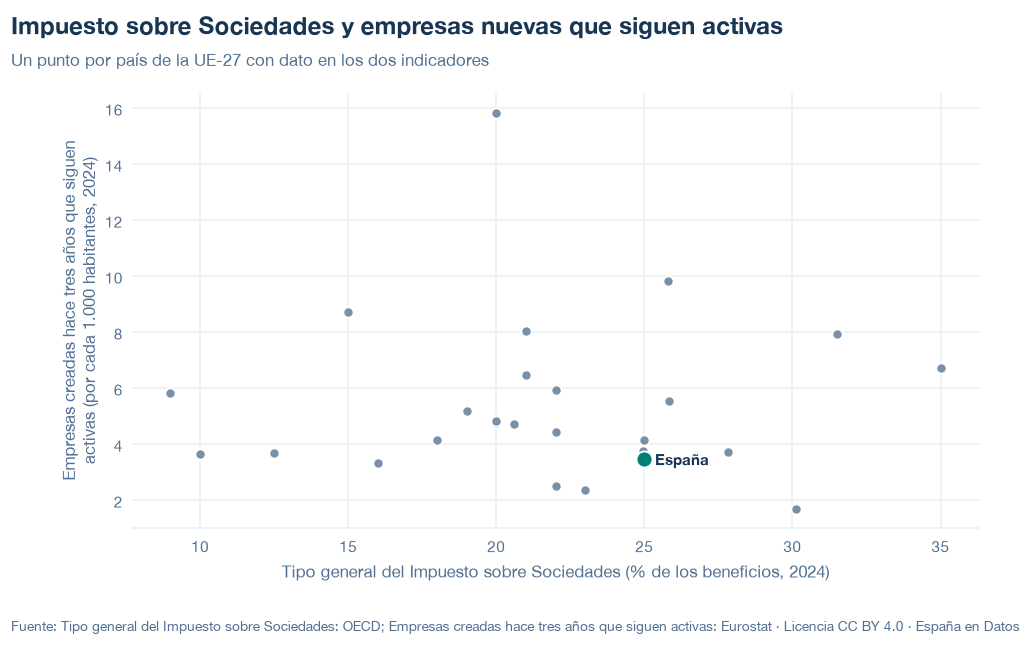

codigo  anio         x         y
   AUT  2024 23.000000  2.362113
   BEL  2024 25.000000  4.150258
   BGR  2024 10.000000  3.661480
   CZE  2024 21.000000  6.461781
   DEU  2024 30.133026  1.702872
   DNK  2024 22.000000  2.497631
   ESP  2024 25.000000  3.464090
   EST  2024 20.000000 15.847244
   FIN  2024 20.000000  4.768507
   FRA  2024 25.825000  5.562864
   GRC  2024 22.000000  4.443143
   HRV  2024 18.000000  4.156172
   HUN  2024  9.000000  5.819006
   IRL  2024 12.500000  3.701641
   ITA  2024 27.810000  3.741604
   LTU  2024 15.000000  8.733525
   LUX  2024 24.940000  3.772041
   LVA  2024 20.000000  4.817481
   MLT  2024 35.000000  6.722952
   NLD  2024 25.800000  9.838576
   POL  2024 19.000000  5.183260
   PRT  2024 31.500000  7.942874
   ROU  2024 16.000000  3.323233
   SVK  2024 21.000000  8.063138
   SVN  2024 22.000000  5.926225
   SWE  2024 20.600000  4.714687


In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/impuesto-sociedades-empresas-nuevas.json y data/impuesto-sociedades-empresas-nuevas.csv


## 6. Fuentes, notas y licencia

- OCDE, Corporate Tax Statistics: `OECD.CTP.TPS,DSD_TAX_CIT@DF_CIT,2.0` (`CIT_C`, `ST`) y `OECD.CTP.TPS,DSD_ETR@DF_ETR_BASELINE,2.1` (tipo efectivo medio, solo notas).
- Eurostat, demografía empresarial: `bd_size` (`ENT_SRVL_NR`, edad `Y3`; natalidad y supervivencia de España, solo notas).
- Eurostat, población a 1 de enero: `demo_pjan`.

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.